# Exploratory Data Analysis — Centrifugal Pump Sensor Data

Operational measurements from centrifugal pumps (A, B, C) that supply demineralized water to boilers at CIRA (Italian Aerospace Research Centre).

**Scope of this notebook**
1. Load and harmonize all CSV files (including format quirks)
2. Dataset inventory and data quality checks
3. Univariate distributions and summary statistics
4. Correlations and relationships between sensors
5. Time-series behavior within operational days
6. Cross-pump and cross-date comparisons
7. Key findings and follow-up questions

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

DATA_DIR = Path(".")
RNG = np.random.default_rng(42)

## 1. Load & Harmonize Data

Files are named `{pump}_{YYYY-MM-DD}.csv`. Most use comma separators and `.` decimals; `A_2024-10-30.csv` uses `;` separators and `,` decimals. Pump-specific column prefixes (`A_`, `B_`, `C_`) are normalized so pumps can be compared side by side.

In [2]:
COLUMN_MAP = {
    "ACR_Mot.PV": "motor_disp_pv",      # m/s — motor accelerometer displacement
    "ACR_Mot.SV": "motor_peak_sv",      # m/s² — motor accelerometer peak
    "ACR_Mot.TV": "motor_temp_tv",      # °C — motor accelerometer contact temp
    "ACR_Pmp.PV": "pump_disp_pv",       # m/s — pump accelerometer displacement
    "ACR_Pmp.SV": "pump_peak_sv",       # m/s² — pump accelerometer peak
    "ACR_Pmp.TV": "pump_temp_tv",       # °C — pump accelerometer contact temp
    "Pres.PV": "outlet_pressure",       # bar — outlet fluid pressure
    "Temp.PV": "motor_casing_temp",     # °C — motor casing temperature
    "Barometer": "barometer",           # mbar — atmospheric pressure
    "Temperature": "ambient_temp",      # °C — ambient temperature
}

SENSOR_COLS = list(COLUMN_MAP.values())
VIBRATION_COLS = ["motor_disp_pv", "motor_peak_sv", "pump_disp_pv", "pump_peak_sv"]
TEMP_COLS = ["motor_temp_tv", "pump_temp_tv", "motor_casing_temp", "ambient_temp"]
PRESSURE_COLS = ["outlet_pressure", "barometer"]


def detect_csv_format(path: Path) -> dict:
    """Detect delimiter and decimal based on the header line."""
    header = path.read_text(encoding="utf-8").splitlines()[0]
    if ";" in header:
        return {"sep": ";", "decimal": ","}
    return {"sep": ",", "decimal": "."}


def load_pump_file(path: Path) -> pd.DataFrame:
    pump, date = path.stem.split("_", 1)
    fmt = detect_csv_format(path)
    df = pd.read_csv(path, **fmt)

    rename = {}
    for col in df.columns:
        if col == "Timestamp":
            continue
        if col in ("Barometer", "Temperature"):
            rename[col] = COLUMN_MAP[col]
        elif col.startswith(f"{pump}_"):
            suffix = col[len(pump) + 1 :]
            if suffix in COLUMN_MAP:
                rename[col] = COLUMN_MAP[suffix]

    df = df.rename(columns=rename)
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], utc=True)

    for col in SENSOR_COLS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    df["pump"] = pump
    df["date"] = date
    df["file"] = path.name
    return df


csv_files = sorted(DATA_DIR.glob("*.csv"))
frames = [load_pump_file(p) for p in csv_files]
df = pd.concat(frames, ignore_index=True).sort_values(["pump", "Timestamp"]).reset_index(drop=True)

print(f"Loaded {len(csv_files)} files → {len(df):,} rows × {df.shape[1]} columns")
print("Pumps:", sorted(df["pump"].unique()))
print("Dates:", sorted(df["date"].unique()))
df.head()

Loaded 9 files → 173,730 rows × 14 columns
Pumps: ['A', 'B', 'C']
Dates: ['2024-04-10', '2024-06-11', '2024-10-30']


,Timestamp,motor_disp_pv,motor_peak_sv,motor_temp_tv,pump_disp_pv,pump_peak_sv,pump_temp_tv,outlet_pressure,motor_casing_temp,barometer,ambient_temp,pump,date,file
0,2024-04-10 12:00:00+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4515,18.0617,"1,018.0533",20.4782,A,2024-04-10,A_2024-04-10.csv
1,2024-04-10 12:00:05+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4515,18.0617,"1,018.0533",20.4782,A,2024-04-10,A_2024-04-10.csv
2,2024-04-10 12:00:10+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4515,18.0617,"1,018.0533",20.4782,A,2024-04-10,A_2024-04-10.csv
3,2024-04-10 12:00:15+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4515,18.0617,"1,018.0533",20.4782,A,2024-04-10,A_2024-04-10.csv
4,2024-04-10 12:00:20+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4515,18.0617,"1,018.0533",20.4128,A,2024-04-10,A_2024-04-10.csv


## 2. Dataset Inventory

In [3]:
inventory = (
    df.groupby(["file", "pump", "date"], as_index=False)
    .agg(
        rows=("Timestamp", "size"),
        start=("Timestamp", "min"),
        end=("Timestamp", "max"),
        missing_cells=("Timestamp", lambda s: int(df.loc[s.index, SENSOR_COLS].isna().sum().sum())),
    )
)
inventory["duration_h"] = (inventory["end"] - inventory["start"]).dt.total_seconds() / 3600
inventory["median_dt_s"] = [
    df.loc[df["file"] == f, "Timestamp"].sort_values().diff().dt.total_seconds().median()
    for f in inventory["file"]
]
inventory

,file,pump,date,rows,start,end,missing_cells,duration_h,median_dt_s
0,A_2024-04-10.csv,A,2024-04-10,4981,2024-04-10 12:00:00+00:00,2024-04-10 13:59:59+00:00,270,1.9997,1.0000
1,A_2024-06-11.csv,A,2024-06-11,21429,2024-06-11 10:00:00+00:00,2024-06-11 15:59:59+00:00,6119,5.9997,1.0000
2,A_2024-10-30.csv,A,2024-10-30,21600,2024-10-30 10:30:00+00:00,2024-10-30 16:29:59+00:00,24,5.9997,1.0000
3,B_2024-04-10.csv,B,2024-04-10,4981,2024-04-10 12:00:00+00:00,2024-04-10 13:59:59+00:00,558,1.9997,1.0000
4,B_2024-06-11.csv,B,2024-06-11,35829,2024-06-11 06:00:00+00:00,2024-06-11 15:59:59+00:00,6045,9.9997,1.0000
5,B_2024-10-30.csv,B,2024-10-30,29700,2024-10-30 08:15:00+00:00,2024-10-30 16:29:59+00:00,39096,8.2497,1.0000
6,C_2024-04-10.csv,C,2024-04-10,4981,2024-04-10 12:00:00+00:00,2024-04-10 13:59:59+00:00,252,1.9997,1.0000
7,C_2024-06-11.csv,C,2024-06-11,21429,2024-06-11 10:00:00+00:00,2024-06-11 15:59:59+00:00,5888,5.9997,1.0000
8,C_2024-10-30.csv,C,2024-10-30,28800,2024-10-30 08:30:00+00:00,2024-10-30 16:29:59+00:00,140663,7.9997,1.0000


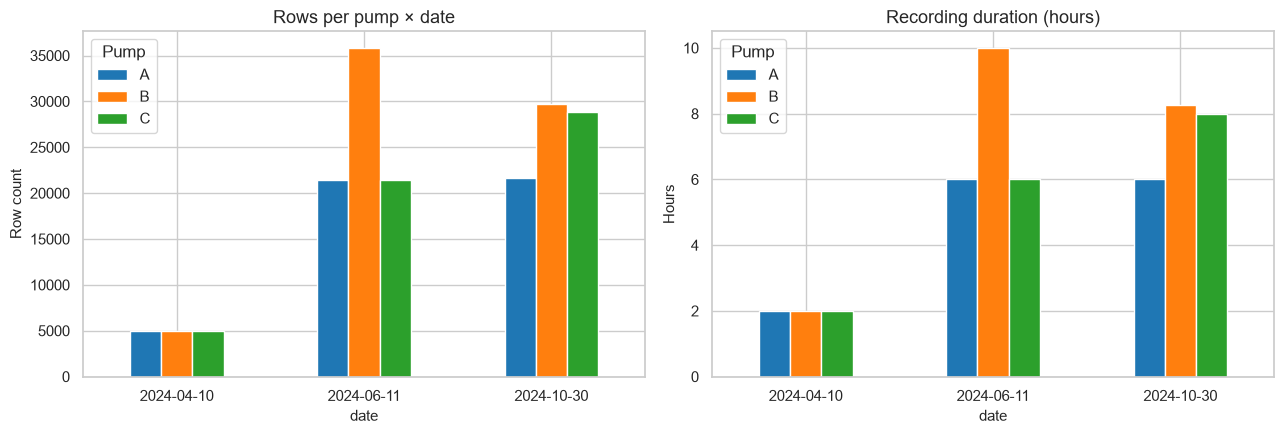

Sampling interval (median seconds between rows):


,mean,min,max
date,,,
2024-04-10,1.0000,1.0000,1.0000
2024-06-11,1.0000,1.0000,1.0000
2024-10-30,1.0000,1.0000,1.0000


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pivot_rows = inventory.pivot(index="date", columns="pump", values="rows")
pivot_rows.plot(kind="bar", ax=axes[0], rot=0, color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[0].set_title("Rows per pump × date")
axes[0].set_ylabel("Row count")
axes[0].legend(title="Pump")

pivot_dur = inventory.pivot(index="date", columns="pump", values="duration_h")
pivot_dur.plot(kind="bar", ax=axes[1], rot=0, color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[1].set_title("Recording duration (hours)")
axes[1].set_ylabel("Hours")
axes[1].legend(title="Pump")

plt.tight_layout()
plt.show()

print("Sampling interval (median seconds between rows):")
display(inventory.groupby("date")["median_dt_s"].describe()[["mean", "min", "max"]])

## 3. Data Quality

In [5]:
missing = (
    df.groupby(["pump", "date"])[SENSOR_COLS]
    .apply(lambda g: g.isna().sum())
    .astype(int)
)
missing["total_missing"] = missing.sum(axis=1)
missing_pct = (
    df.groupby(["pump", "date"])[SENSOR_COLS]
    .apply(lambda g: 100 * g.isna().mean())
    .round(2)
)

print("Missing value counts by pump × date")
display(missing)

print("\nMissing value % by pump × date (sensor columns)")
display(missing_pct)

Missing value counts by pump × date


motor_disp_pv  motor_peak_sv  motor_temp_tv  pump_disp_pv  \
pump date                                                                    
A    2024-04-10             14             14             14            34   
     2024-06-11            458            458            458           471   
     2024-10-30              2              2              2             6   
B    2024-04-10             55             55             55            24   
     2024-06-11            477            477            477           622   
     2024-10-30              3              3              3            67   
C    2024-04-10             35             35             35            12   
     2024-06-11            383            383            383           438   
     2024-10-30             15             68          27303            56   

                 pump_peak_sv  pump_temp_tv  outlet_pressure  \
pump date                                                      
A    2024-04-10            34            34               19   
     2024-06-11           471           471              306   
     2024-10-30             6             6                0   
B    2024-04-10            24           138                4   
     2024-06-11           622          1799              288   
     2024-10-30            67            67                0   
C    2024-04-10            12            12                3   
     2024-06-11           438           438              453   
     2024-10-30           241         26640                0   

                 motor_casing_temp  barometer  ambient_temp  total_missing  
pump date                                                                   
A    2024-04-10                 76         16            15            270  
     2024-06-11                474        341          2211           6119  
     2024-10-30                  0          0             0             24  
B    2024-04-10                172         16            15            558  
     2024-06-11                479        340           464           6045  
     2024-10-30                  0      19443         19443          39096  
C    2024-04-10                 77         16            15            252  
     2024-06-11                420        341          2211           5888  
     2024-10-30              28740      28800         28800         140663


Missing value % by pump × date (sensor columns)


motor_disp_pv  motor_peak_sv  motor_temp_tv  pump_disp_pv  \
pump date                                                                    
A    2024-04-10         0.2800         0.2800         0.2800        0.6800   
     2024-06-11         2.1400         2.1400         2.1400        2.2000   
     2024-10-30         0.0100         0.0100         0.0100        0.0300   
B    2024-04-10         1.1000         1.1000         1.1000        0.4800   
     2024-06-11         1.3300         1.3300         1.3300        1.7400   
     2024-10-30         0.0100         0.0100         0.0100        0.2300   
C    2024-04-10         0.7000         0.7000         0.7000        0.2400   
     2024-06-11         1.7900         1.7900         1.7900        2.0400   
     2024-10-30         0.0500         0.2400        94.8000        0.1900   

                 pump_peak_sv  pump_temp_tv  outlet_pressure  \
pump date                                                      
A    2024-04-10        0.6800        0.6800           0.3800   
     2024-06-11        2.2000        2.2000           1.4300   
     2024-10-30        0.0300        0.0300           0.0000   
B    2024-04-10        0.4800        2.7700           0.0800   
     2024-06-11        1.7400        5.0200           0.8000   
     2024-10-30        0.2300        0.2300           0.0000   
C    2024-04-10        0.2400        0.2400           0.0600   
     2024-06-11        2.0400        2.0400           2.1100   
     2024-10-30        0.8400       92.5000           0.0000   

                 motor_casing_temp  barometer  ambient_temp  
pump date                                                    
A    2024-04-10             1.5300     0.3200        0.3000  
     2024-06-11             2.2100     1.5900       10.3200  
     2024-10-30             0.0000     0.0000        0.0000  
B    2024-04-10             3.4500     0.3200        0.3000  
     2024-06-11             1.3400     0.9500        1.3000  
     2024-10-30             0.0000    65.4600       65.4600  
C    2024-04-10             1.5500     0.3200        0.3000  
     2024-06-11             1.9600     1.5900       10.3200  
     2024-10-30            99.7900   100.0000      100.0000

In [6]:
dup_ts = (
    df.groupby(["pump", "date", "Timestamp"])
    .size()
    .reset_index(name="n")
    .query("n > 1")
)
print(f"Duplicate timestamps within pump×date: {len(dup_ts):,}")

# Constant / near-constant columns per file
const_rows = []
for (pump, date), g in df.groupby(["pump", "date"]):
    for col in SENSOR_COLS:
        s = g[col].dropna()
        const_rows.append({
            "pump": pump,
            "date": date,
            "column": col,
            "n_unique": int(s.nunique()),
            "std": float(s.std()) if len(s) else np.nan,
        })
const_df = pd.DataFrame(const_rows)
near_const = const_df.query("n_unique <= 3")
print(f"Near-constant series (≤3 unique values): {len(near_const)}")
if len(near_const):
    display(near_const.sort_values(["pump", "date", "column"]).head(20))

Duplicate timestamps within pump×date: 0
Near-constant series (≤3 unique values): 3


,pump,date,column,n_unique,std
89,C,2024-10-30,ambient_temp,0,NaN
88,C,2024-10-30,barometer,0,NaN
87,C,2024-10-30,motor_casing_temp,1,0.0000


## 4. Summary Statistics

In [7]:
desc = df[SENSOR_COLS].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["missing"] = df[SENSOR_COLS].isna().sum()
desc["missing_pct"] = (100 * desc["missing"] / len(df)).round(2)
desc

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,missing,missing_pct
motor_disp_pv,"172,288.0000",0.0013,0.0006,0.0003,0.0005,0.0007,0.0009,0.0012,0.0015,0.0028,0.0033,0.0039,1442,0.8300
motor_peak_sv,"172,235.0000",22.1595,48.9864,0.3844,0.3880,0.4228,0.4613,0.4997,20.9463,175.4742,209.1519,456.6258,1495,0.8600
motor_temp_tv,"145,000.0000",36.0236,17.2273,17.7188,18.7891,19.4219,30.0156,37.0078,40.5703,47.5078,53.9609,300.6250,28730,16.5400
pump_disp_pv,"172,000.0000",0.0017,0.0014,0.0000,0.0003,0.0004,0.0006,0.0009,0.0033,0.0040,0.0042,0.0073,1730,1.0000
pump_peak_sv,"171,815.0000",9.5792,19.7347,0.0000,0.3756,0.4131,0.4507,0.5245,20.8980,34.0501,55.2847,637.1081,1915,1.1000
pump_temp_tv,"144,125.0000",38.6504,19.9588,17.6094,18.8828,21.9531,34.5781,40.3672,42.8125,44.2109,45.8359,264.3750,29605,17.0400
outlet_pressure,"172,657.0000",14.9545,19.4523,0.4247,0.4342,0.4504,0.5159,0.6997,40.2613,43.1757,44.6418,46.7089,1073,0.6200
motor_casing_temp,"143,292.0000",34.2259,8.8194,17.9290,18.8442,19.7322,30.0842,35.2242,38.3001,45.6319,53.1736,273.1250,30438,17.5200
barometer,"124,417.0000","1,014.6881",4.2821,"1,009.6072","1,010.1537","1,010.5264","1,011.4638","1,011.8811","1,019.9251","1,022.1042","1,022.4566","1,022.5323",49313,28.3800
ambient_temp,"120,556.0000",24.4455,2.4685,19.0080,19.2171,19.7471,22.9945,25.4339,26.2044,27.4402,27.8272,28.7535,53174,30.6100


In [8]:
means = (
    df.groupby(["pump", "date"])[SENSOR_COLS]
    .mean()
    .round(5)
)
print("Mean sensor values by pump × date")
display(means)

stds = (
    df.groupby(["pump", "date"])[SENSOR_COLS]
    .std()
    .round(5)
)
print("\nStd of sensor values by pump × date")
display(stds)

Mean sensor values by pump × date


motor_disp_pv  motor_peak_sv  motor_temp_tv  pump_disp_pv  \
pump date                                                                    
A    2024-04-10         0.0016         1.7079        28.2836        0.0008   
     2024-06-11         0.0018         3.0136        38.8516        0.0012   
     2024-10-30         0.0021         6.5009        41.6582        0.0018   
B    2024-04-10         0.0008         1.6618        19.1660        0.0011   
     2024-06-11         0.0010        16.8065        34.8417        0.0022   
     2024-10-30         0.0014        98.7281        36.8262        0.0033   
C    2024-04-10         0.0013         2.7239        22.3180        0.0009   
     2024-06-11         0.0012         2.0760        31.0691        0.0008   
     2024-10-30         0.0010         0.4571       123.1944        0.0006   

                 pump_peak_sv  pump_temp_tv  outlet_pressure  \
pump date                                                      
A    2024-04-10        2.7613       23.2559           3.7543   
     2024-06-11        6.7313       40.5505           9.1212   
     2024-10-30       12.9299       39.1080          15.8917   
B    2024-04-10        1.9698       20.9657           3.0569   
     2024-06-11       14.2830       38.6254          25.6489   
     2024-10-30       18.7854       39.5128          32.6370   
C    2024-04-10        4.4838       21.5457           6.6355   
     2024-06-11        5.1318       36.4658           3.7945   
     2024-10-30        0.4415      139.6920           0.6491   

                 motor_casing_temp  barometer  ambient_temp  
pump date                                                    
A    2024-04-10            26.9984 1,018.0780       19.9069  
     2024-06-11            37.7636 1,011.4256       26.2818  
     2024-10-30            40.7000 1,020.4219       23.6931  
B    2024-04-10            19.1753 1,018.0780       19.9069  
     2024-06-11            33.1579 1,011.5122       25.7220  
     2024-10-30            34.9285 1,022.0948       21.3396  
C    2024-04-10            23.6048 1,018.0780       19.9069  
     2024-06-11            31.7741 1,011.4256       26.2818  
     2024-10-30           273.1250        NaN           NaN


Std of sensor values by pump × date


motor_disp_pv  motor_peak_sv  motor_temp_tv  pump_disp_pv  \
pump date                                                                    
A    2024-04-10         0.0005         8.3867         3.4315        0.0008   
     2024-06-11         0.0006         5.2987         5.0363        0.0013   
     2024-10-30         0.0008         7.9368         9.3933        0.0014   
B    2024-04-10         0.0002         4.2821         0.3267        0.0008   
     2024-06-11         0.0003        14.9781         6.5243        0.0012   
     2024-10-30         0.0003        79.1621         6.7500        0.0013   
C    2024-04-10         0.0005         5.7073         2.4295        0.0009   
     2024-06-11         0.0004         5.2985         3.8491        0.0006   
     2024-10-30         0.0002         0.0311       120.9843        0.0002   

                 pump_peak_sv  pump_temp_tv  outlet_pressure  \
pump date                                                      
A    2024-04-10       13.6628        2.1310          11.1624   
     2024-06-11       13.2159        3.1785          16.6213   
     2024-10-30       16.2024        4.9223          19.1711   
B    2024-04-10        5.5817        1.2640          10.1557   
     2024-06-11       13.6064        7.7703          20.7693   
     2024-10-30       35.5274        5.3420          15.5613   
C    2024-04-10        9.9375        1.7376          15.0534   
     2024-06-11       15.3555        6.6158          10.9387   
     2024-10-30        0.0324      110.6168           0.0979   

                 motor_casing_temp  barometer  ambient_temp  
pump date                                                    
A    2024-04-10             3.0776     0.0593        0.3400  
     2024-06-11             4.8086     0.5377        0.6586  
     2024-10-30             8.6991     0.5356        1.2562  
B    2024-04-10             0.5903     0.0593        0.3400  
     2024-06-11             5.2936     0.5527        1.2911  
     2024-10-30             5.7056     0.3364        1.3219  
C    2024-04-10             3.1776     0.0593        0.3400  
     2024-06-11             3.7759     0.5377        0.6586  
     2024-10-30             0.0000        NaN           NaN

## 5. Univariate Distributions

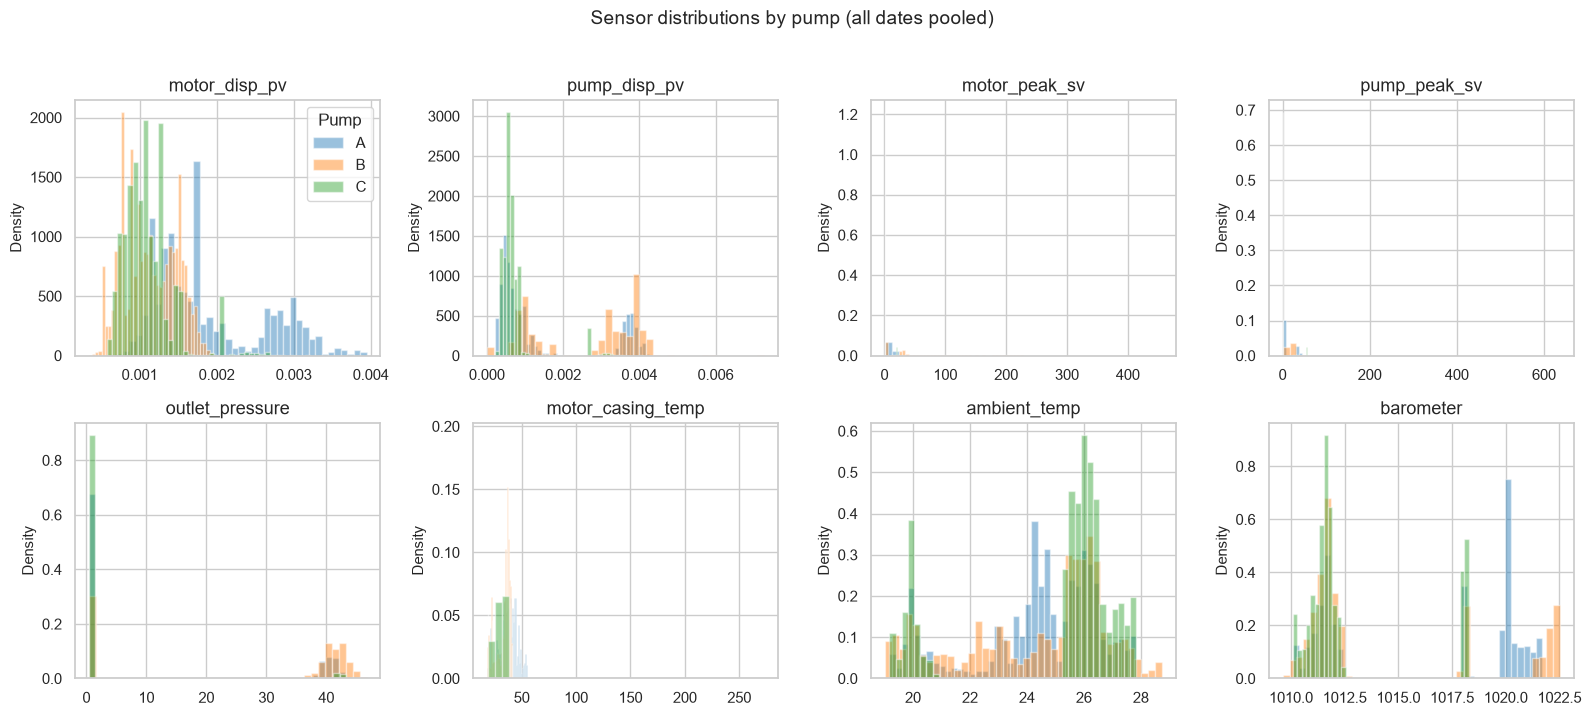

In [9]:
plot_cols = [
    "motor_disp_pv", "pump_disp_pv",
    "motor_peak_sv", "pump_peak_sv",
    "outlet_pressure", "motor_casing_temp",
    "ambient_temp", "barometer",
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), plot_cols):
    for pump, color in zip(["A", "B", "C"], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
        subset = df.loc[df["pump"] == pump, col].dropna()
        ax.hist(subset, bins=40, alpha=0.45, label=pump, color=color, density=True)
    ax.set_title(col)
    ax.set_ylabel("Density")
axes[0, 0].legend(title="Pump")
fig.suptitle("Sensor distributions by pump (all dates pooled)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

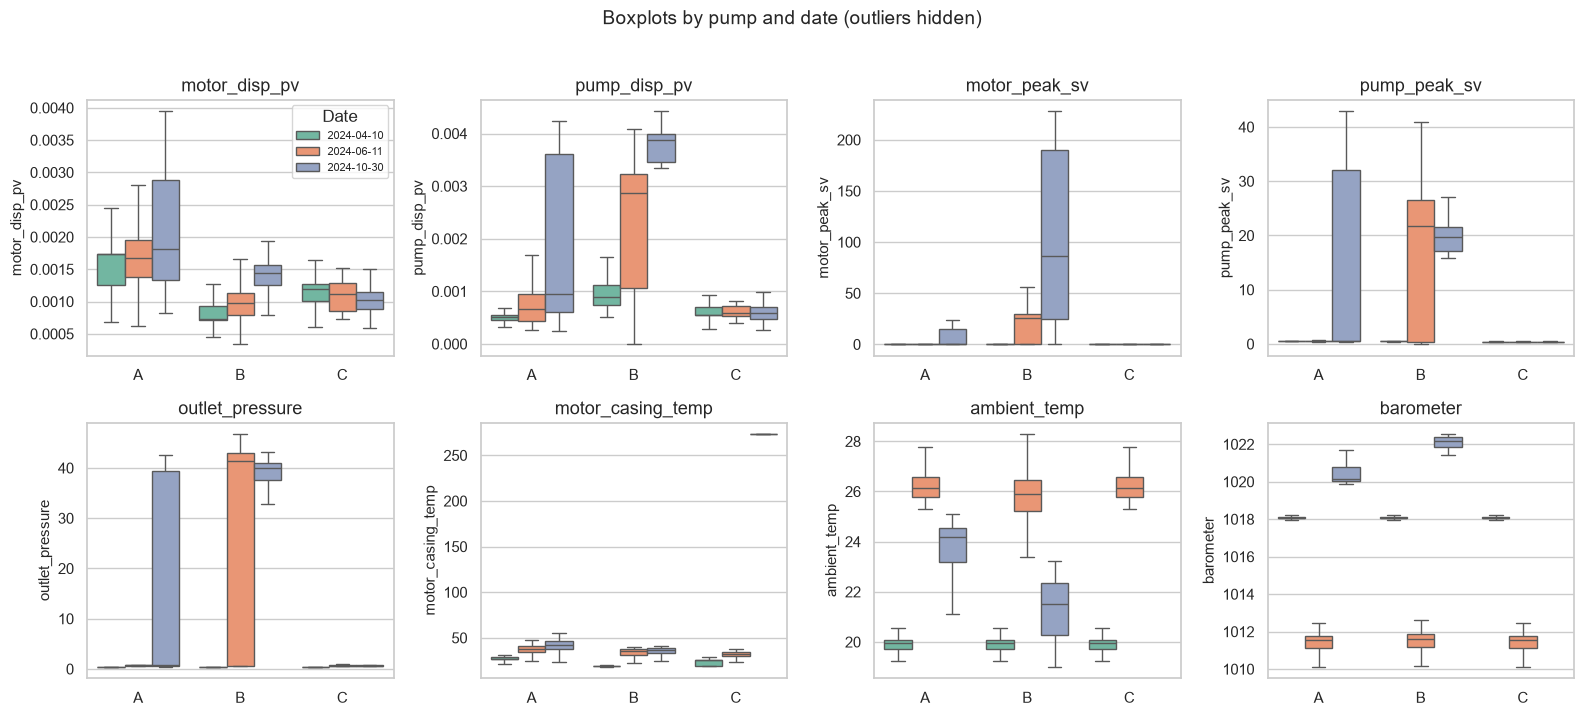

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(
        data=df, x="pump", y=col, hue="date",
        ax=ax, showfliers=False, palette="Set2",
    )
    ax.set_title(col)
    ax.set_xlabel("")
    if ax is not axes[0, 0]:
        ax.legend_.remove() if ax.get_legend() else None
axes[0, 0].legend(title="Date", fontsize=8)
fig.suptitle("Boxplots by pump and date (outliers hidden)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 6. Correlations

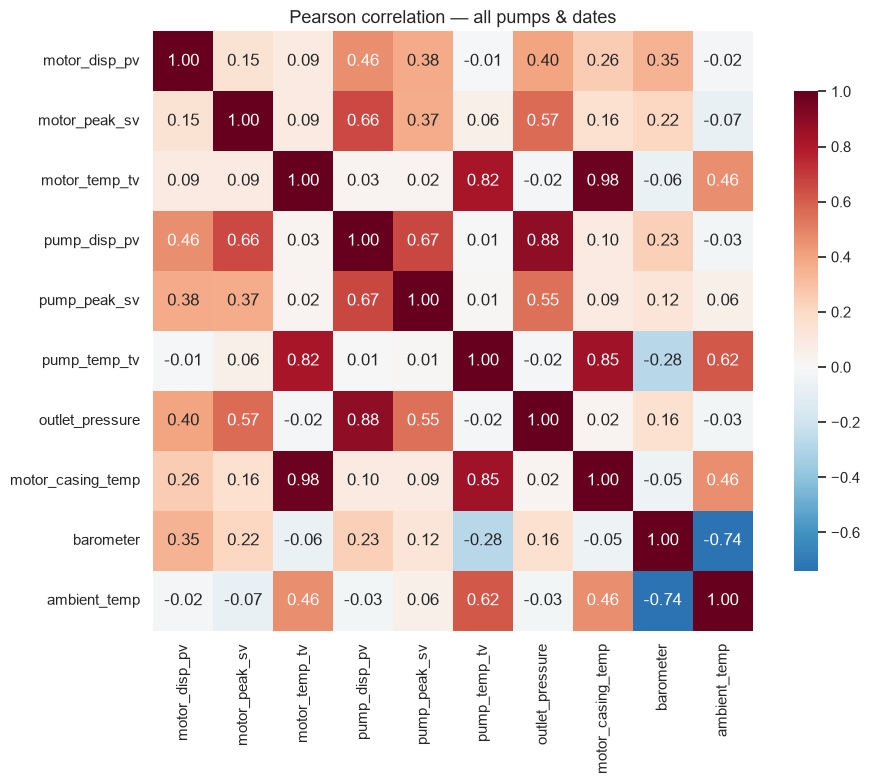

In [11]:
corr = df[SENSOR_COLS].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    square=True, ax=ax, cbar_kws={"shrink": 0.8},
)
ax.set_title("Pearson correlation — all pumps & dates")
plt.tight_layout()
plt.show()

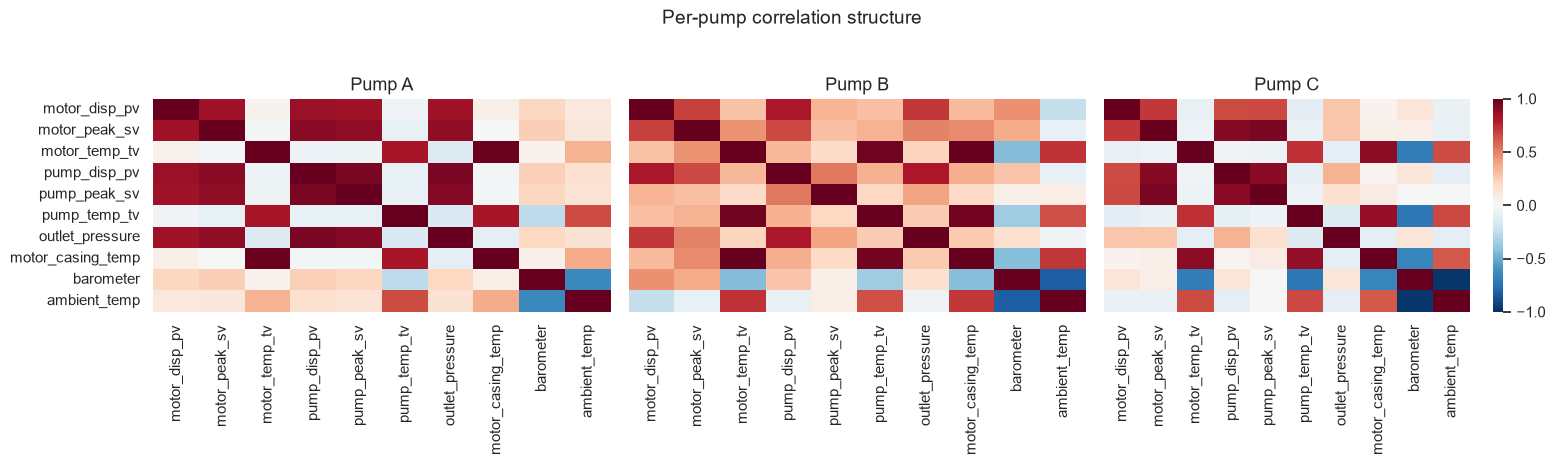

Top |correlations|


,feature_a,feature_b,r,abs_r
27,motor_temp_tv,motor_casing_temp,0.9793,0.9793
36,pump_disp_pv,outlet_pressure,0.8799,0.8799
57,pump_temp_tv,motor_casing_temp,0.8465,0.8465
25,motor_temp_tv,pump_temp_tv,0.8166,0.8166
89,barometer,ambient_temp,-0.7394,0.7394
34,pump_disp_pv,pump_peak_sv,0.6663,0.6663
13,motor_peak_sv,pump_disp_pv,0.6586,0.6586
59,pump_temp_tv,ambient_temp,0.6156,0.6156
16,motor_peak_sv,outlet_pressure,0.5666,0.5666
46,pump_peak_sv,outlet_pressure,0.5491,0.5491


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, pump in zip(axes, ["A", "B", "C"]):
    c = df.loc[df["pump"] == pump, SENSOR_COLS].corr()
    sns.heatmap(c, cmap="RdBu_r", center=0, ax=ax, cbar=ax is axes[-1], vmin=-1, vmax=1)
    ax.set_title(f"Pump {pump}")
fig.suptitle("Per-pump correlation structure", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

# Strongest absolute correlations (excluding self)
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .rename("r")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
)
pairs["abs_r"] = pairs["r"].abs()
print("Top |correlations|")
display(pairs.sort_values("abs_r", ascending=False).head(12))

## 7. Time-Series Views

Downsample to 1-minute means for readable plots (raw sampling is ~1 Hz).

In [13]:
def resample_minute(frame: pd.DataFrame) -> pd.DataFrame:
    out = (
        frame.set_index("Timestamp")[SENSOR_COLS]
        .resample("1min")
        .mean()
        .dropna(how="all")
        .reset_index()
    )
    out["pump"] = frame["pump"].iloc[0]
    out["date"] = frame["date"].iloc[0]
    return out


minute = pd.concat(
    [resample_minute(g) for _, g in df.groupby(["pump", "date"], sort=False)],
    ignore_index=True,
)
print(f"Minute-level rows: {len(minute):,} (from {len(df):,} raw)")
minute.head()

Minute-level rows: 2,995 (from 173,730 raw)


,Timestamp,motor_disp_pv,motor_peak_sv,motor_temp_tv,pump_disp_pv,pump_peak_sv,pump_temp_tv,outlet_pressure,motor_casing_temp,barometer,ambient_temp,pump,date
0,2024-04-10 12:00:00+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4515,18.0617,"1,018.0497",20.4346,A,2024-04-10
1,2024-04-10 12:01:00+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4507,18.0300,"1,018.0420",20.3862,A,2024-04-10
2,2024-04-10 12:02:00+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4526,18.1029,"1,018.0538",20.3815,A,2024-04-10
3,2024-04-10 12:03:00+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4535,18.2153,"1,018.0621",20.3908,A,2024-04-10
4,2024-04-10 12:04:00+00:00,0.0012,0.4268,17.9766,0.0005,0.6073,18.2188,0.4534,18.2486,"1,018.0298",20.3919,A,2024-04-10


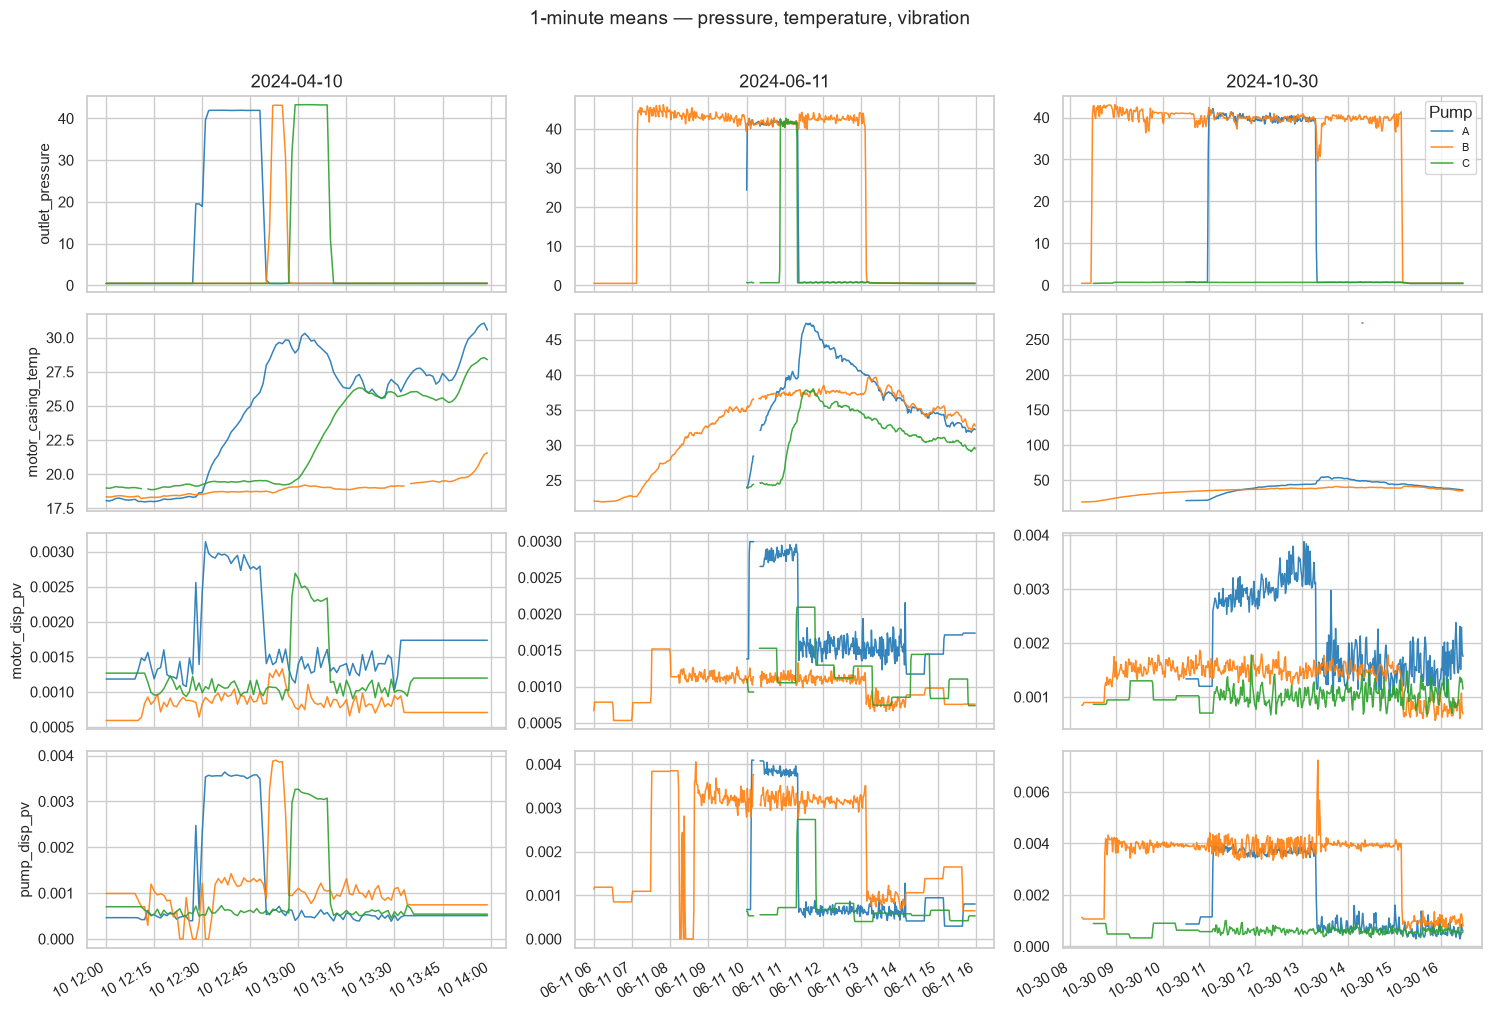

In [14]:
ts_cols = ["outlet_pressure", "motor_casing_temp", "motor_disp_pv", "pump_disp_pv"]
dates = sorted(df["date"].unique())

fig, axes = plt.subplots(len(ts_cols), len(dates), figsize=(15, 10), sharex="col")
if len(dates) == 1:
    axes = np.array(axes).reshape(len(ts_cols), 1)

for j, date in enumerate(dates):
    for i, col in enumerate(ts_cols):
        ax = axes[i, j]
        for pump, color in zip(["A", "B", "C"], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
            sub = minute[(minute["date"] == date) & (minute["pump"] == pump)]
            if sub.empty:
                continue
            ax.plot(sub["Timestamp"], sub[col], label=pump, color=color, lw=1.1, alpha=0.9)
        if i == 0:
            ax.set_title(date)
        if j == 0:
            ax.set_ylabel(col)
        if i == 0 and j == len(dates) - 1:
            ax.legend(title="Pump", fontsize=8)

fig.suptitle("1-minute means — pressure, temperature, vibration", y=1.01, fontsize=14)
fig.autofmt_xdate(rotation=30)
plt.tight_layout()
plt.show()

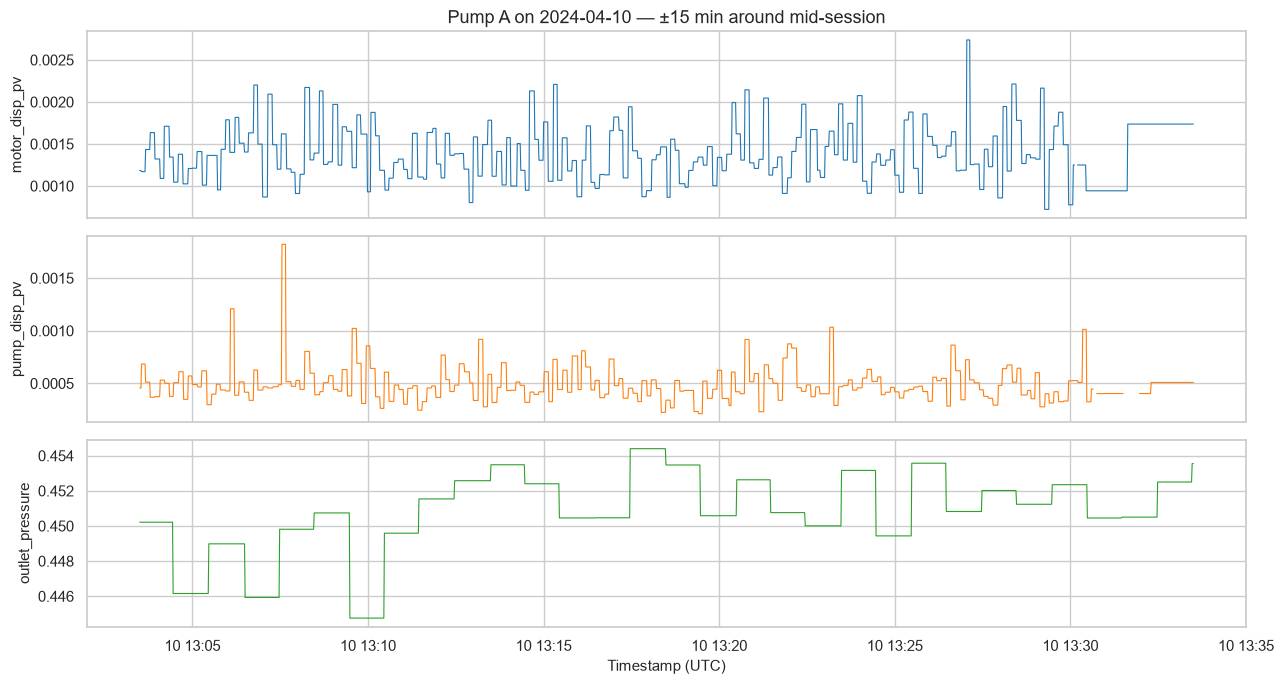

In [15]:
# Zoom: one representative day × pump for vibration detail
example_date = dates[0]
example_pump = "A"
ex = df[(df["date"] == example_date) & (df["pump"] == example_pump)].copy()

# Plot a 30-minute window near the middle of the recording
mid = ex["Timestamp"].iloc[len(ex) // 2]
window = ex[(ex["Timestamp"] >= mid - pd.Timedelta(minutes=15)) &
            (ex["Timestamp"] <= mid + pd.Timedelta(minutes=15))]

fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
axes[0].plot(window["Timestamp"], window["motor_disp_pv"], color="#1f77b4", lw=0.8)
axes[0].set_ylabel("motor_disp_pv")
axes[0].set_title(f"Pump {example_pump} on {example_date} — ±15 min around mid-session")

axes[1].plot(window["Timestamp"], window["pump_disp_pv"], color="#ff7f0e", lw=0.8)
axes[1].set_ylabel("pump_disp_pv")

axes[2].plot(window["Timestamp"], window["outlet_pressure"], color="#2ca02c", lw=0.8)
axes[2].set_ylabel("outlet_pressure")
axes[2].set_xlabel("Timestamp (UTC)")

plt.tight_layout()
plt.show()

## 8. Pump & Date Comparisons

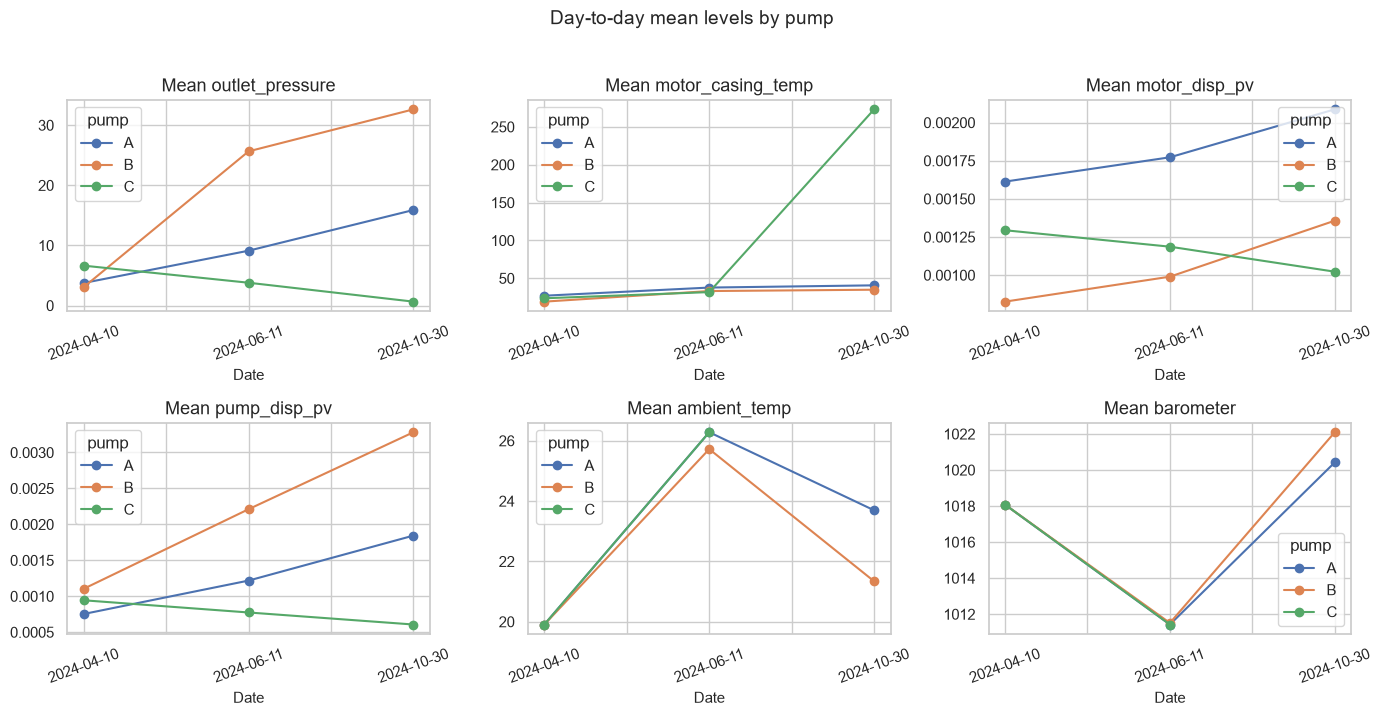

In [16]:
compare_cols = [
    "outlet_pressure", "motor_casing_temp",
    "motor_disp_pv", "pump_disp_pv",
    "ambient_temp", "barometer",
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), compare_cols):
    means_plot = df.groupby(["date", "pump"])[col].mean().unstack("pump")
    means_plot.plot(marker="o", ax=ax)
    ax.set_title(f"Mean {col}")
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Day-to-day mean levels by pump", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
# Relative change vs first available date for each pump
first_dates = df.groupby("pump")["date"].min().to_dict()

delta_rows = []
for pump, g in df.groupby("pump"):
    base_date = first_dates[pump]
    base = g.loc[g["date"] == base_date, SENSOR_COLS].mean()
    for date, gd in g.groupby("date"):
        if date == base_date:
            continue
        delta = gd[SENSOR_COLS].mean() - base
        row = {"pump": pump, "date": date, "vs": base_date}
        row.update(delta.round(5).to_dict())
        delta_rows.append(row)

deltas = pd.DataFrame(delta_rows)
print("Mean change relative to each pump's earliest recording day")
display(deltas)

Mean change relative to each pump's earliest recording day


,pump,date,vs,motor_disp_pv,motor_peak_sv,motor_temp_tv,pump_disp_pv,pump_peak_sv,pump_temp_tv,outlet_pressure,motor_casing_temp,barometer,ambient_temp
0,A,2024-06-11,2024-04-10,0.0002,1.3058,10.5681,0.0005,3.9700,17.2947,5.3669,10.7653,-6.6524,6.3749
1,A,2024-10-30,2024-04-10,0.0005,4.7930,13.3746,0.0011,10.1686,15.8521,12.1374,13.7016,2.3438,3.7862
2,B,2024-06-11,2024-04-10,0.0002,15.1448,15.6756,0.0011,12.3131,17.6596,22.5920,13.9826,-6.5658,5.8151
3,B,2024-10-30,2024-04-10,0.0005,97.0663,17.6602,0.0022,16.8156,18.5470,29.5801,15.7532,4.0167,1.4327
4,C,2024-06-11,2024-04-10,-0.0001,-0.6480,8.7511,-0.0002,0.6479,14.9201,-2.8410,8.1692,-6.6524,6.3749
5,C,2024-10-30,2024-04-10,-0.0003,-2.2669,100.8764,-0.0003,-4.0423,118.1462,-5.9864,249.5202,NaN,NaN


## 9. Pairwise Relationships (sample)

Scatter plots on a stratified sample to keep rendering fast.

KeyError: 'pump'

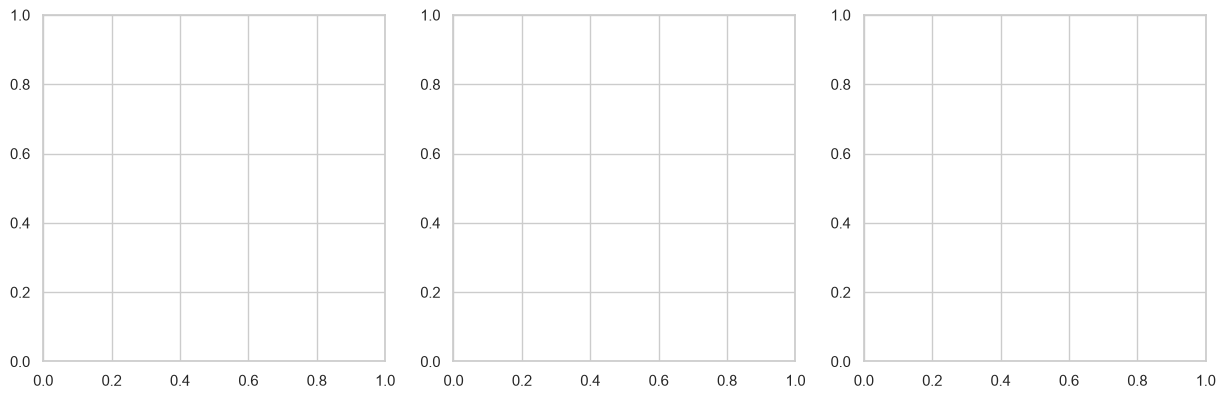

In [18]:
sample = (
    df.dropna(subset=["outlet_pressure", "motor_casing_temp", "motor_disp_pv", "pump_disp_pv"])
    .groupby(["pump", "date"], group_keys=False)
    .apply(lambda g: g.sample(n=min(800, len(g)), random_state=42))
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
pairs = [
    ("outlet_pressure", "motor_casing_temp"),
    ("motor_disp_pv", "pump_disp_pv"),
    ("ambient_temp", "motor_casing_temp"),
]
for ax, (x, y) in zip(axes, pairs):
    for pump, color in zip(["A", "B", "C"], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
        sub = sample[sample["pump"] == pump]
        ax.scatter(sub[x], sub[y], s=6, alpha=0.25, label=pump, color=color)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
axes[0].legend(title="Pump", markerscale=3)
fig.suptitle("Selected bivariate relationships (stratified sample)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 10. Simple Anomaly Flags

Per pump×date, flag points beyond median ± 5×IQR on key vibration/pressure channels.

In [19]:
def iqr_outlier_mask(s: pd.Series, k: float = 5.0) -> pd.Series:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    if iqr == 0 or np.isnan(iqr):
        return pd.Series(False, index=s.index)
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return (s < lo) | (s > hi)


flag_cols = ["motor_disp_pv", "pump_disp_pv", "outlet_pressure", "motor_casing_temp"]
outlier_summary = []

for (pump, date), g in df.groupby(["pump", "date"]):
    row = {"pump": pump, "date": date, "n": len(g)}
    any_flag = pd.Series(False, index=g.index)
    for col in flag_cols:
        mask = iqr_outlier_mask(g[col])
        row[f"{col}_outliers"] = int(mask.sum())
        any_flag |= mask.fillna(False)
    row["any_flagged"] = int(any_flag.sum())
    row["pct_flagged"] = round(100 * any_flag.mean(), 3)
    outlier_summary.append(row)

outlier_df = pd.DataFrame(outlier_summary).sort_values(["pump", "date"])
outlier_df

,pump,date,n,motor_disp_pv_outliers,pump_disp_pv_outliers,outlet_pressure_outliers,motor_casing_temp_outliers,any_flagged,pct_flagged
0,A,2024-04-10,4981,0,477,512,0,593,11.9050
1,A,2024-06-11,21429,0,3822,4383,0,4383,20.4540
2,A,2024-10-30,21600,0,0,0,0,0,0.0000
3,B,2024-04-10,4981,0,320,361,0,388,7.7900
4,B,2024-06-11,35829,0,0,0,0,0,0.0000
5,B,2024-10-30,29700,0,840,5585,0,5643,19.0000
6,C,2024-04-10,4981,183,713,719,0,726,14.5750
7,C,2024-06-11,21429,0,1800,1620,0,3376,15.7540
8,C,2024-10-30,28800,0,0,2093,0,2093,7.2670


## 11. Findings Checklist

Run the cell below to print an automated snapshot of notable patterns from the loaded data.

In [20]:
print("=== EDA SNAPSHOT ===\n")
print(f"Files loaded: {df['file'].nunique()}  |  Rows: {len(df):,}  |  Pumps: {sorted(df['pump'].unique())}")
print(f"Dates: {sorted(df['date'].unique())}")
print(f"Overall missing cells (sensors): {int(df[SENSOR_COLS].isna().sum().sum()):,}"
      f" ({100 * df[SENSOR_COLS].isna().mean().mean():.3f}% average per-column)")

print("\nRecording coverage (hours):")
print(inventory.pivot(index="date", columns="pump", values="duration_h").round(2).to_string())

print("\nHighest mean outlet pressure (pump × date):")
top_p = means["outlet_pressure"].sort_values(ascending=False).head(3)
print(top_p.to_string())

print("\nHighest mean motor displacement (pump × date):")
top_v = means["motor_disp_pv"].sort_values(ascending=False).head(3)
print(top_v.to_string())

print("\nMost correlated sensor pair:")
best = pairs.sort_values("abs_r", ascending=False).iloc[0]
print(f"  {best['feature_a']} ↔ {best['feature_b']}: r = {best['r']:.3f}")

print("\nIQR outlier rates (any of key channels):")
print(outlier_df[["pump", "date", "pct_flagged"]].to_string(index=False))

print("\nNotes for interpretation:")
print("  • A_2024-10-30.csv uses ';' separators and ',' decimals — handled in the loader.")
print("  • Column names in files use *.PV for pressure/temp (README mentions *.SV).")
print("  • Sessions differ in length; April files are much shorter than June/October.")
print("  • Ambient temperature and barometer are shared environmental context, not pump-specific.")

=== EDA SNAPSHOT ===

Files loaded: 9  |  Rows: 173,730  |  Pumps: ['A', 'B', 'C']
Dates: ['2024-04-10', '2024-06-11', '2024-10-30']
Overall missing cells (sensors): 198,915 (11.450% average per-column)

Recording coverage (hours):
pump            A       B      C
date                            
2024-04-10 2.0000  2.0000 2.0000
2024-06-11 6.0000 10.0000 6.0000
2024-10-30 6.0000  8.2500 8.0000

Highest mean outlet pressure (pump × date):
pump  date      
B     2024-10-30   32.6370
      2024-06-11   25.6489
A     2024-10-30   15.8917

Highest mean motor displacement (pump × date):
pump  date      
A     2024-10-30   0.0021
      2024-06-11   0.0018
      2024-04-10   0.0016

Most correlated sensor pair:


AttributeError: 'list' object has no attribute 'sort_values'

## Next Steps

- Align sessions on a common operational phase (startup / steady-state / shutdown) before comparing pumps.
- Engineer rolling vibration statistics (RMS, crest factor) for condition monitoring.
- Model outlet pressure / casing temperature as a function of ambient conditions and pump identity.
- Investigate whether missing accelerometer samples cluster in time (sensor dropouts vs. downtime).